# Figure 3B — Module Activity Per Contrast

Standalone -- reloads `kinase_module_assignments.csv` (from `fig1a_kinase_module_heatmap.ipynb` / `kinase_module_activity.ipynb`) and `kl_en_res_lightweight.pkl` rather than sharing kernel state.

Three visualizations of the same underlying module x contrast NES data: a heatmap, a bubble plot (size = fraction of module kinases individually significant), and a per-module trajectory panel across timepoints.

## 0. Imports, paths, and standalone reload

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

enr_f      = "/ix/djishnu/Aaron_F/proteomics_proj/Results/KL_motif_enrichment_res/out_files/kl_en_res_lightweight.pkl"
module_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Caroline_site_KEA_clustering/out_files"
out_path   = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3b"
os.makedirs(f"{out_path}/figures", exist_ok=True)
os.makedirs(f"{out_path}/out_files", exist_ok=True)

with open(enr_f, "rb") as f:
    lightweight = pickle.load(f)
ser_thr_tables = lightweight["enrichment_tables"]["ser_thr"]

module_df = pd.read_csv(f"{module_dir}/kinase_module_assignments.csv")
module_ids = sorted(module_df["module"].unique())

# Dropped the 3 IL6-vs-IL10 head-to-head contrasts -- keeping only the 6
# cytokine-vs-baseline (over_0min) contrasts.
sign_logp_cols = [
    "sign.logP.IL6_20min_over_0min",
    "sign.logP.IL6_45min_over_0min",
    "sign.logP.IL6_90min_over_0min",
    "sign.logP.IL10_20min_over_0min",
    "sign.logP.IL10_45min_over_0min",
    "sign.logP.IL10_90min_over_0min",
]
contrast_labels = [c.split(".")[-1] for c in sign_logp_cols]
all_kinases = module_df["kinase"].tolist()

print(f"Loaded: {len(ser_thr_tables)} contrasts, {len(module_df)} module-labeled kinases, "
      f"{len(module_ids)} modules")

Loaded: 9 contrasts, 83 module-labeled kinases, 12 modules


## 1. Pull NES per kinase per contrast

Continuous, signed activity measure.

In [2]:
nes_matrix = pd.DataFrame(index=all_kinases, columns=contrast_labels, dtype=float)
for contrast, label in zip(sign_logp_cols, contrast_labels):
    tbl = ser_thr_tables[contrast]
    nes_matrix[label] = tbl.loc[all_kinases, "NES"]

nes_matrix.to_csv(f"{out_path}/out_files/kinase_NES_matrix.csv")
nes_matrix.head()

,IL6_20min_over_0min,IL6_45min_over_0min,IL6_90min_over_0min,IL10_20min_over_0min,IL10_45min_over_0min,IL10_90min_over_0min
AAK1,1.220577,1.155057,1.36882,1.300324,1.293439,1.380704
AKT1,1.808784,1.832986,1.6161,1.486928,1.53859,1.934254
AKT2,1.831304,1.797673,1.542448,1.296886,1.491919,1.777589
AKT3,2.025161,1.966273,1.634204,1.446744,1.48788,1.832863
ATM,1.289983,1.125855,-1.133833,1.222106,1.133403,-1.020662


## 2. Module activity score per contrast (mean NES across module kinases)

Kept with a plain integer module index (`module_score`) so it can be reused directly for the trajectory panel below -- a display-only copy with `"Module N (n=...)"` labels is made separately for the heatmap/bubble plot.

In [3]:
module_score = pd.DataFrame(index=module_ids, columns=contrast_labels, dtype=float)

for m in module_ids:
    kins_in_module = module_df.loc[module_df["module"] == m, "kinase"].tolist()
    module_score.loc[m] = nes_matrix.loc[kins_in_module].mean(axis=0)

module_score.to_csv(f"{out_path}/out_files/module_activity_scores.csv")

module_score_display = module_score.copy()
module_score_display.index = [f"Module {m} (n={sum(module_df.module == m)})" for m in module_ids]

module_score.round(2)

,IL6_20min_over_0min,IL6_45min_over_0min,IL6_90min_over_0min,IL10_20min_over_0min,IL10_45min_over_0min,IL10_90min_over_0min
1,1.22,1.13,1.29,1.34,1.19,1.19
2,0.94,-0.20,0.96,1.11,1.07,0.50
3,1.11,0.90,-0.37,1.20,1.21,-0.79
4,1.18,1.14,0.38,1.09,1.12,-0.00
5,1.23,0.91,-0.69,1.50,1.15,-1.22
6,1.05,0.41,-1.31,1.29,1.05,-1.30
7,1.15,1.13,1.21,1.18,1.32,1.22
8,-0.58,0.44,1.29,1.13,1.26,1.43
9,1.14,1.24,1.22,1.14,-0.30,1.39
10,0.59,1.14,1.32,1.12,1.14,1.32


## 2b. Exclude modules for the final (main-figure) version

Modules 4, 9, 10, and 12 are dropped for the final figures below -- the supplement sections above (3-5) keep every module.

In [4]:
EXCLUDED_MODULES = [4, 9, 10, 12]

module_ids_final = [m for m in module_ids if m not in EXCLUDED_MODULES]
module_score_final = module_score.drop(index=EXCLUDED_MODULES, errors="ignore")

module_score_display_final = module_score_final.copy()
module_score_display_final.index = [
    f"Module {m} (n={sum(module_df.module == m)})" for m in module_ids_final
]

print(f"Modules: {len(module_ids)} total -> {len(module_ids_final)} after excluding {EXCLUDED_MODULES}")

Modules: 12 total -> 8 after excluding [4, 9, 10, 12]


## 3. Heatmap -- SUPPLEMENT (all modules) -- diverging colormap since NES is signed

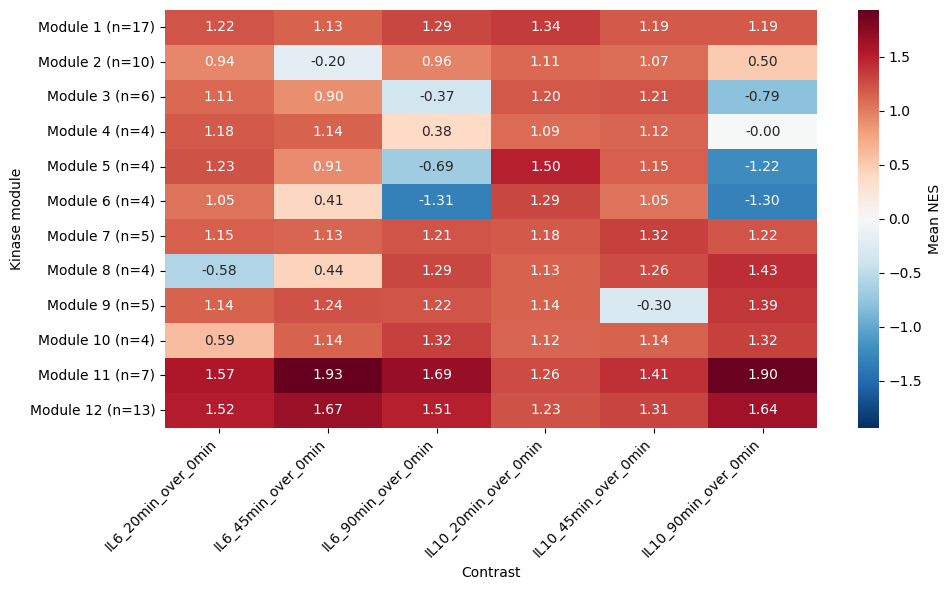

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3b/figures/fig3b_module_activity_heatmap.png


In [5]:
fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(module_ids))))
vmax = np.nanmax(np.abs(module_score_display.values))
sns.heatmap(
    module_score_display.astype(float), cmap="RdBu_r", center=0,
    vmin=-vmax, vmax=vmax, annot=True, fmt=".2f",
    cbar_kws={"label": "Mean NES"}, ax=ax
)
ax.set_xlabel("Contrast")
ax.set_ylabel("Kinase module")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig_out = f"{out_path}/figures/fig3b_module_activity_heatmap.png"
plt.savefig(fig_out, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_out}")

## 4. Bubble plot -- SUPPLEMENT (all modules) -- size = fraction of module kinases individually significant

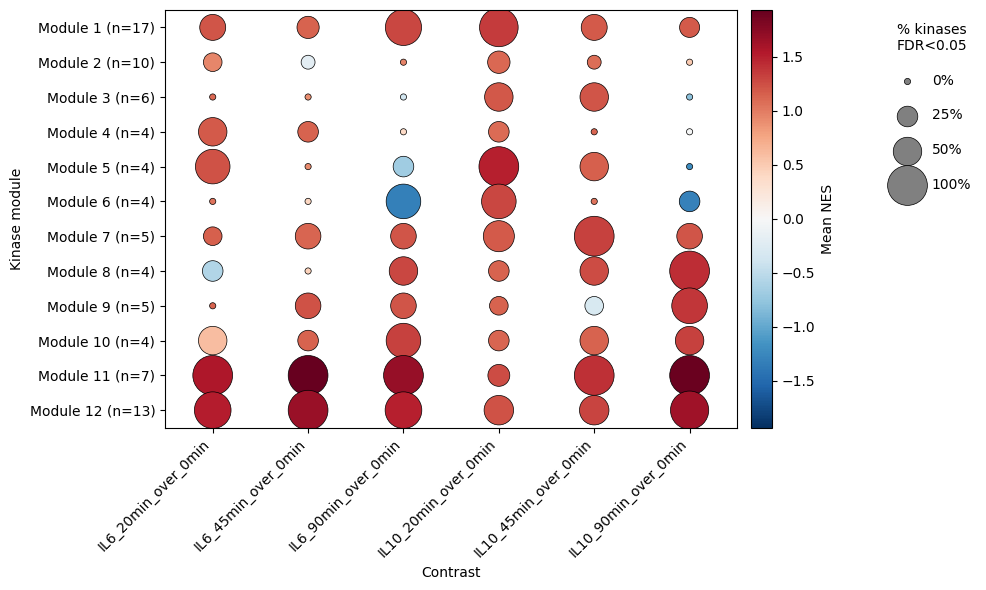

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3b/figures/fig3b_FULL_module_activity_bubbleplot.png


In [6]:
sig_frac = pd.DataFrame(index=module_score_display.index, columns=contrast_labels, dtype=float)

for m, label in zip(module_ids, module_score_display.index):
    kins_in_module = module_df.loc[module_df["module"] == m, "kinase"].tolist()
    for contrast, contrast_label in zip(sign_logp_cols, contrast_labels):
        tbl = ser_thr_tables[contrast]
        n_sig = (tbl.loc[kins_in_module, "FDR"] < 0.05).sum()
        sig_frac.loc[label, contrast_label] = n_sig / len(kins_in_module)

fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(module_ids))))

n_rows, n_cols = module_score_display.shape
x_pos, y_pos = np.meshgrid(range(n_cols), range(n_rows))

vmax = np.nanmax(np.abs(module_score_display.values))
sizes = sig_frac.values.flatten() * 800 + 20

sc = ax.scatter(
    x_pos.flatten(), y_pos.flatten(),
    c=module_score_display.values.flatten(),
    s=sizes,
    cmap="RdBu_r", vmin=-vmax, vmax=vmax,
    edgecolors="black", linewidths=0.5,
)

ax.set_xticks(range(n_cols))
ax.set_xticklabels(module_score_display.columns, rotation=45, ha="right")
ax.set_yticks(range(n_rows))
ax.set_yticklabels(module_score_display.index)
ax.set_xlabel("Contrast")
ax.set_ylabel("Kinase module")
ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(-0.5, n_rows - 0.5)
ax.invert_yaxis()

cbar = plt.colorbar(sc, ax=ax, label="Mean NES", pad=0.02)

for frac in [0.0, 0.25, 0.5, 1.0]:
    ax.scatter([], [], s=frac * 800 + 20, c="gray", edgecolors="black",
               linewidths=0.5, label=f"{int(frac*100)}%")
ax.legend(
    title="% kinases\nFDR<0.05", loc="upper left", bbox_to_anchor=(1.25, 1),
    labelspacing=1.5, frameon=False
)

plt.tight_layout()
fig_out = f"{out_path}/figures/fig3b_FULL_module_activity_bubbleplot.png"
plt.savefig(f"{out_path}/figures/fig3b_FULL_module_activity_bubbleplot.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{out_path}/figures/fig3b_FULL_module_activity_bubbleplot.svg", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_out}")

## 5. NES trajectory panel -- SUPPLEMENT (all modules) -- one subplot per module, across timepoints

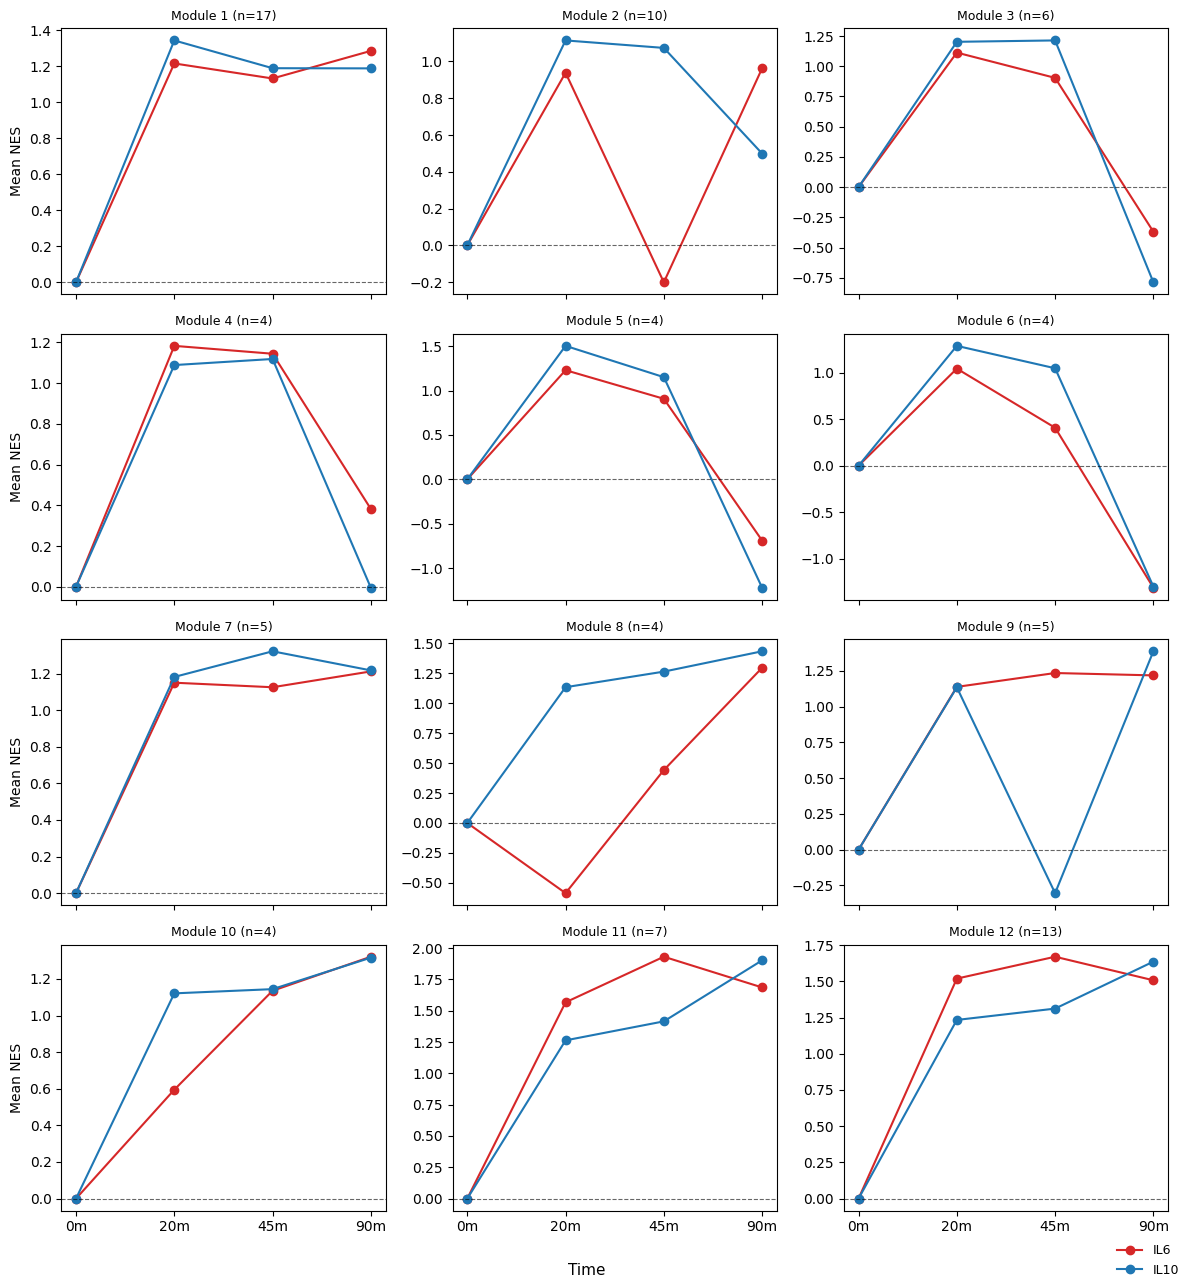

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3b/figures/fig3b_module_NES_trajectory_panel.png


In [7]:
def parse_contrast_label(label):
    cytokine, rest = label.split("_", 1)          # "IL6", "20min_over_0min"
    timepoint = rest.split("min")[0] + "m"          # "20m"
    return cytokine, timepoint

label_lookup = {}  # (cytokine, timepoint) -> contrast_label
for label in contrast_labels:
    cytokine, timepoint = parse_contrast_label(label)
    label_lookup[(cytokine, timepoint)] = label

time_order = ["0m", "20m", "45m", "90m"]
IL6_COLOR, IL10_COLOR = "#d62728", "#1f77b4"

ncols = 3
nrows = int(np.ceil(len(module_ids) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows), sharex=True)
axes = axes.flatten()

for i, m in enumerate(module_ids):
    ax = axes[i]
    for cytokine, color in [("IL6", IL6_COLOR), ("IL10", IL10_COLOR)]:
        y = [0.0]  # NES=0 at baseline by convention, not computed
        for t in time_order[1:]:
            contrast_label = label_lookup[(cytokine, t)]
            y.append(module_score.loc[m, contrast_label])
        ax.plot(range(len(time_order)), y, marker="o", color=color, label=cytokine)

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
    ax.set_xticks(range(len(time_order)))
    ax.set_xticklabels(time_order)
    n_kins = sum(module_df.module == m)
    ax.set_title(f"Module {m} (n={n_kins})", fontsize=9)
    if i % ncols == 0:
        ax.set_ylabel("Mean NES")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

handles = [plt.Line2D([0], [0], color=IL6_COLOR, marker="o", label="IL6"),
           plt.Line2D([0], [0], color=IL10_COLOR, marker="o", label="IL10")]
fig.legend(handles=handles, loc="lower right", fontsize=9, frameon=False)
fig.text(0.5, 0.0, "Time", ha="center", fontsize=11)

plt.tight_layout(rect=[0, 0.02, 1, 1])
fig_out = f"{out_path}/figures/fig3b_module_NES_trajectory_panel.png"
plt.savefig(fig_out, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_out}")

## 6. Heatmap -- FINAL (modules 4, 9, 10, 12 excluded)

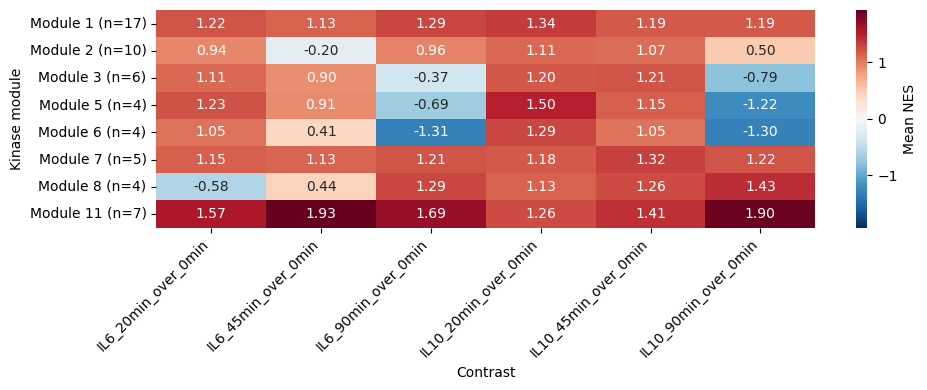

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3b/figures/fig3b_final_module_activity_heatmap.png


In [8]:
fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(module_ids_final))))
vmax = np.nanmax(np.abs(module_score_display_final.values))
sns.heatmap(
    module_score_display_final.astype(float), cmap="RdBu_r", center=0,
    vmin=-vmax, vmax=vmax, annot=True, fmt=".2f",
    cbar_kws={"label": "Mean NES"}, ax=ax
)
ax.set_xlabel("Contrast")
ax.set_ylabel("Kinase module")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig_out = f"{out_path}/figures/fig3b_final_module_activity_heatmap.png"
plt.savefig(fig_out, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_out}")

## 7. Bubble plot -- FINAL (modules 4, 9, 10, 12 excluded)

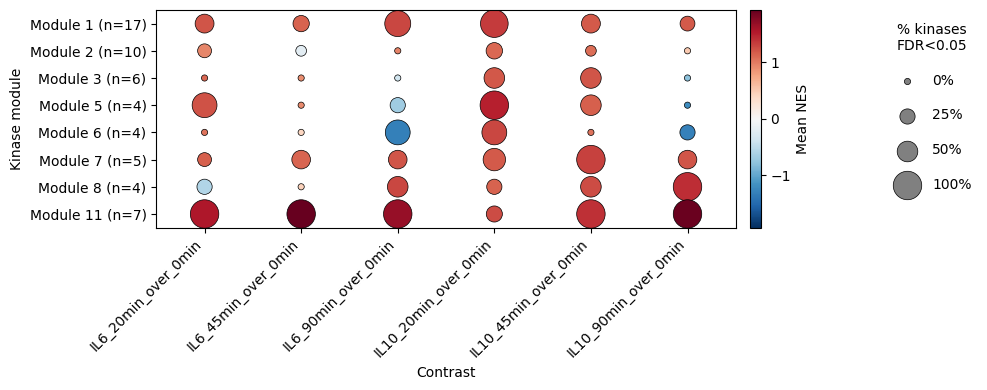

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3b/figures/fig3b_final_module_activity_bubbleplot.png


In [9]:
sig_frac_final = pd.DataFrame(index=module_score_display_final.index, columns=contrast_labels, dtype=float)

for m, label in zip(module_ids_final, module_score_display_final.index):
    kins_in_module = module_df.loc[module_df["module"] == m, "kinase"].tolist()
    for contrast, contrast_label in zip(sign_logp_cols, contrast_labels):
        tbl = ser_thr_tables[contrast]
        n_sig = (tbl.loc[kins_in_module, "FDR"] < 0.05).sum()
        sig_frac_final.loc[label, contrast_label] = n_sig / len(kins_in_module)

fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(module_ids_final))))

n_rows, n_cols = module_score_display_final.shape
x_pos, y_pos = np.meshgrid(range(n_cols), range(n_rows))

vmax = np.nanmax(np.abs(module_score_display_final.values))
sizes = sig_frac_final.values.flatten() * 400 + 20

sc = ax.scatter(
    x_pos.flatten(), y_pos.flatten(),
    c=module_score_display_final.values.flatten(),
    s=sizes,
    cmap="RdBu_r", vmin=-vmax, vmax=vmax,
    edgecolors="black", linewidths=0.5,
)

ax.set_xticks(range(n_cols))
ax.set_xticklabels(module_score_display_final.columns, rotation=45, ha="right")
ax.set_yticks(range(n_rows))
ax.set_yticklabels(module_score_display_final.index)
ax.set_xlabel("Contrast")
ax.set_ylabel("Kinase module")
ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(-0.5, n_rows - 0.5)
ax.invert_yaxis()

cbar = plt.colorbar(sc, ax=ax, label="Mean NES", pad=0.02)

for frac in [0.0, 0.25, 0.5, 1.0]:
    ax.scatter([], [], s=frac * 400 + 20, c="gray", edgecolors="black",
               linewidths=0.5, label=f"{int(frac*100)}%")
ax.legend(
    title="% kinases\nFDR<0.05", loc="upper left", bbox_to_anchor=(1.25, 1),
    labelspacing=1.5, frameon=False
)

plt.tight_layout()
fig_out = f"{out_path}/figures/fig3b_final_module_activity_bubbleplot.png"
plt.savefig(f"{out_path}/figures/fig3b_final_module_activity_bubbleplot.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{out_path}/figures/fig3b_final_module_activity_bubbleplot.svg", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_out}")

## 8. NES trajectory panel -- FINAL (modules 4, 9, 10, 12 excluded)

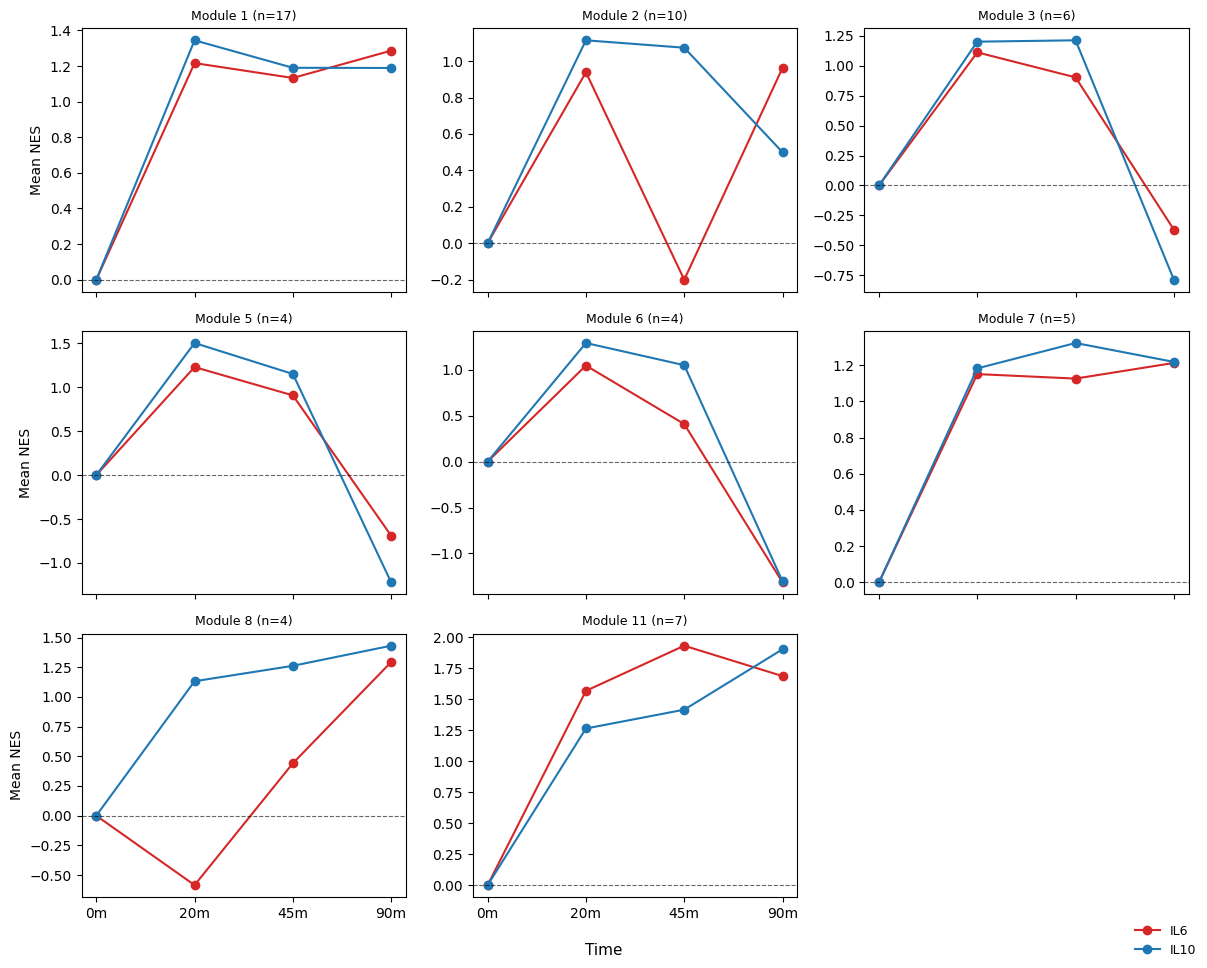

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3b/figures/fig3b_final_module_NES_trajectory_panel.png


In [10]:
ncols = 3
nrows = int(np.ceil(len(module_ids_final) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows), sharex=True)
axes = axes.flatten()

for i, m in enumerate(module_ids_final):
    ax = axes[i]
    for cytokine, color in [("IL6", IL6_COLOR), ("IL10", IL10_COLOR)]:
        y = [0.0]
        for t in time_order[1:]:
            contrast_label = label_lookup[(cytokine, t)]
            y.append(module_score_final.loc[m, contrast_label])
        ax.plot(range(len(time_order)), y, marker="o", color=color, label=cytokine)

    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
    ax.set_xticks(range(len(time_order)))
    ax.set_xticklabels(time_order)
    n_kins = sum(module_df.module == m)
    ax.set_title(f"Module {m} (n={n_kins})", fontsize=9)
    if i % ncols == 0:
        ax.set_ylabel("Mean NES")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

handles = [plt.Line2D([0], [0], color=IL6_COLOR, marker="o", label="IL6"),
           plt.Line2D([0], [0], color=IL10_COLOR, marker="o", label="IL10")]
fig.legend(handles=handles, loc="lower right", fontsize=9, frameon=False)
fig.text(0.5, 0.0, "Time", ha="center", fontsize=11)

plt.tight_layout(rect=[0, 0.02, 1, 1])
fig_out = f"{out_path}/figures/fig3b_final_module_NES_trajectory_panel.png"
plt.savefig(fig_out, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_out}")